In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit,transpile
from qiskit_aer import AerSimulator
import qiskit.quantum_info as qi
from qiskit.visualization import plot_histogram

In [3]:
g = 0.5
delta_t = 1
omega = 2*g
N = 30
simualtor_aer = AerSimulator()

## Measuring Z

In [4]:
sz_2 = []
for niter in range(0,N):
    qc = QuantumCircuit(2,2)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.rz(-omega*delta_t,0)
        qc.reset(1)
    qc.measure(0,0)
    job = simualtor_aer.run(qc,shots = 1024)
    results = job.result().get_counts()
    valor = (results.get('00',0) - ((results.get('01',0)))) / 1024
    sz_2.append(-valor)


### Drawing of the circuit

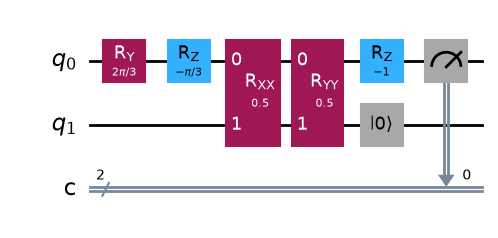

In [5]:

qc = QuantumCircuit(2,2)
qc.ry(np.pi-np.pi/3,0)
qc.rz(-np.pi/3,0)
qc.rxx(g*delta_t,0,1)
qc.ryy(g*delta_t,0,1)
qc.rz(-omega*delta_t,0)
qc.reset(1)
qc.measure(0,0)
qc.draw('mpl')

## Measuring X

In [6]:
sx_2 = []
for niter in range(0,N):
    qc = QuantumCircuit(2,2)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.rz(-omega*delta_t,0)
        qc.reset(1)
    qc.h(0)
    qc.measure(0,0)
    job = simualtor_aer.run(qc,shots = 1024)
    results = job.result().get_counts()
    valor = (results.get('00', 0) - (results.get('0q', 0))) / 1024
    sx_2.append(valor)

### Drawing of the Circuit

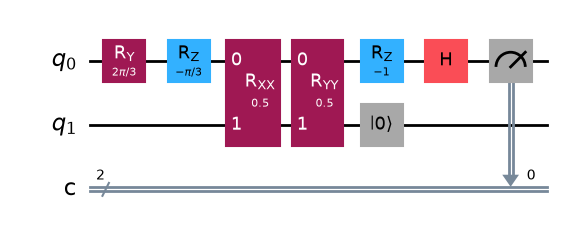

In [7]:
qc = QuantumCircuit(2,2)
qc.ry(np.pi-np.pi/3,0)
qc.rz(-np.pi/3,0)
qc.rxx(g*delta_t,0,1)
qc.ryy(g*delta_t,0,1)
qc.rz(-omega*delta_t,0)
qc.reset(1)
qc.h(0)
qc.measure(0,0)
qc.draw('mpl')

## Measuring Y

In [8]:
sy_2 = []
for niter in range(0,N):
    qc = QuantumCircuit(2,2)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.rz(-omega*delta_t,0)
        qc.reset(1)
    qc.sdg(0)
    qc.h(0)
    qc.measure(0,0)
    job = simualtor_aer.run(qc,shots = 1024)
    results = job.result().get_counts()
    valor = (results.get('00', 0) - (results.get('01', 0))) / 1024
    sy_2.append(-valor)

### Drawing of the circuit

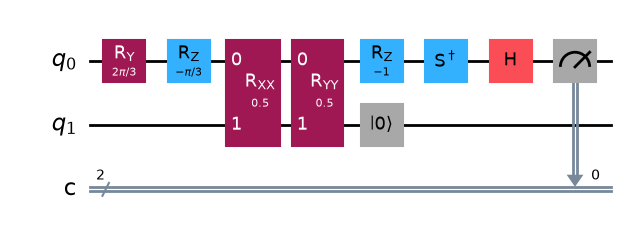

In [9]:
qc = QuantumCircuit(2,2)
qc.ry(np.pi-np.pi/3,0)
qc.rz(-np.pi/3,0)
qc.rxx(g*delta_t,0,1)
qc.ryy(g*delta_t,0,1)
qc.rz(-omega*delta_t,0)
qc.reset(1)
qc.sdg(0)
qc.h(0)
qc.measure(0,0)
qc.draw('mpl')

## Plotting Expected Values

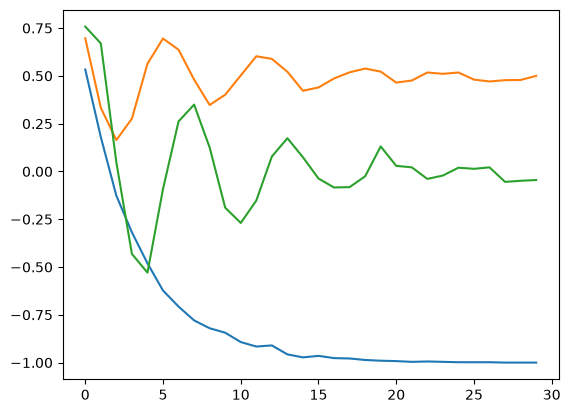

In [10]:
time = np.arange(N) * delta_t
plt.plot(time, sz_2)
plt.plot(time, sx_2)
plt.plot(time, sy_2)

datos = np.column_stack((time, sx_2, sy_2, sz_2))

np.savetxt(
    "qiskit2_sxsysz.txt",
    datos,
    header="t sx sy sz",
    fmt="%.10f"
)